# Task 1 — Nigeria Food Price Analysis

3. **Task 1a** — Build a national food inflation index over time
4. **Task 1b** — Compare wholesale vs. retail prices
5. **Task 1c** — Map where in Nigeria food is most expensive



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import re

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


## 2. Load the data

Row 2 of the CSV is an HXL metadata row (e.g. `#date`, `#adm1+name`) rather than real data,
so it's skipped on load.

In [2]:
df = pd.read_csv('nigeria_food_prices.csv', skiprows=[1])
df['date'] = pd.to_datetime(df['date'])

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 76,810 rows x 16 columns


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,175.92,1.54
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,150.18,1.31
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,358.70,3.14
3,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Sorghum,65,KG,actual,Wholesale,NGN,155.61,1.36
4,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,pulses and nuts,Beans (niebe),120,KG,actual,Wholesale,NGN,196.87,1.72


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 76810 entries, 0 to 76809
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          76810 non-null  datetime64[us]
 1   admin1        76810 non-null  str           
 2   admin2        76810 non-null  str           
 3   market        76810 non-null  str           
 4   market_id     76810 non-null  int64         
 5   latitude      76810 non-null  float64       
 6   longitude     76810 non-null  float64       
 7   category      76810 non-null  str           
 8   commodity     76810 non-null  str           
 9   commodity_id  76810 non-null  int64         
 10  unit          76810 non-null  str           
 11  priceflag     76810 non-null  str           
 12  pricetype     76810 non-null  str           
 13  currency      76810 non-null  str           
 14  price         76810 non-null  float64       
 15  usdprice      76810 non-null  float64       
dt

### 2.1 Missing values

Checking every column for missing (null) values before doing anything else.

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing) == 0:
    print("No missing values in any column.")
else:
    print(missing)


No missing values in any column.


### 2.2 Duplicate rows and invalid prices

Two more basic checks: exact duplicate rows, and prices that are zero or negative
(which would be data-entry errors, since a food price can't be ≤ 0).

In [5]:
n_duplicates = df.duplicated().sum()
n_nonpositive_price = (df['price'] <= 0).sum()

print(f"Duplicate rows: {n_duplicates}")
print(f"Rows with price <= 0: {n_nonpositive_price}")


Duplicate rows: 0
Rows with price <= 0: 0


**Result:** this dataset has **no missing values, no duplicate rows, and no non-positive
prices** — so no rows need to be dropped for those reasons. (This is checked explicitly
rather than assumed, since a real analysis should never skip this step.)


In [6]:
df['priceflag'].value_counts()


priceflag
actual              52260
aggregate           24013
actual,aggregate      537
Name: count, dtype: int64



### 2.3 Cleaning decision

Since there are no missing values or invalid prices, cleaning here is minimal — we just
keep the dataframe as-is. If this dataset *did* have missing prices, the standard approach
would be `df.dropna(subset=['price', 'usdprice'])`, which is included below defensively
(it won't remove anything here, but protects the rest of the notebook if the data changes).

In [7]:
df = df.dropna(subset=['price', 'usdprice'])
df = df[df['price'] > 0]
print(f"Rows after cleaning: {len(df):,} (unchanged, as expected)")


Rows after cleaning: 76,810 (unchanged, as expected)


---
## 3. Task 1a — Food inflation trends over time

### 3.1 Why we can't just average raw prices

A kilo of rice and a kilo of pepper cost very different amounts, and commodities are added
to the dataset at different times (e.g. most non-cereal categories only start in 2016). So
simply averaging every raw price each month would be biased by *which* commodities happen to
be reported that month, not by real inflation.

**The fix — a price relative index:** for every unique series (one commodity, in one market,
with one price type), rebase its very first recorded price to 100. From then on, its value
tells us "% of its original price" — e.g. 150 means that specific item is now 50% more
expensive than when we first saw it. Because every series now starts at the same point (100),
they can be safely averaged across the whole country.

In [8]:
# A "series" = one specific thing being tracked repeatedly over time
df['series_id'] = df['commodity'] + ' | ' + df['market'] + ' | ' + df['unit'] + ' | ' + df['pricetype']

df_sorted = df.sort_values('date')
first_price = df_sorted.groupby('series_id')['price'].transform('first')
df_sorted['price_relative'] = df_sorted['price'] / first_price * 100

print(f"Number of unique series tracked: {df_sorted['series_id'].nunique():,}")
df_sorted[['date', 'series_id', 'price', 'price_relative']].head()


Number of unique series tracked: 1,846


,date,series_id,price,price_relative
0,2002-01-15,Maize | Jibia (CBM) | KG | Wholesale,175.92,100.0
1,2002-01-15,Millet | Jibia (CBM) | KG | Wholesale,150.18,100.0
2,2002-01-15,Rice (imported) | Jibia (CBM) | KG | Wholesale,358.70,100.0
3,2002-01-15,Sorghum | Jibia (CBM) | KG | Wholesale,155.61,100.0
4,2002-01-15,Beans (niebe) | Jibia (CBM) | KG | Wholesale,196.87,100.0


### 3.2 Handling outliers: mean vs. median

Before averaging these price-relative values into one national number per month, let's check
whether there are any extreme outliers that could distort a simple average.

In [9]:
print("Distribution of price_relative (should mostly be near 100):")
print(df_sorted['price_relative'].describe())
print()
print("Most extreme values:")
print(df_sorted['price_relative'].nlargest(5).values)


Distribution of price_relative (should mostly be near 100):
count    76810.000000
mean       171.685491
std        367.320901
min          0.769231
25%        100.000000
50%        133.333333
75%        200.000000
max      61728.395062
Name: price_relative, dtype: float64

Most extreme values:
[61728.39506173 51851.85185185 44444.44444444  8875.
  8000.        ]


A handful of series have a price_relative in the **thousands** — almost certainly a data
entry error in their very first recorded price (an unusually low first value makes every later
value look like a huge jump). A simple **mean** would let a single one of these bad points
distort the entire national index for that month.

**The fix:** use the **median** instead of the mean (a median isn't affected by a few extreme
values), and additionally **winsorize** — clip the 1st and 99th percentile — as a second layer
of protection.

In [10]:
p1, p99 = df_sorted['price_relative'].quantile([0.01, 0.99])
print(f"Clipping price_relative to the [{p1:.1f}, {p99:.1f}] range (1st-99th percentile)")

df_sorted['price_relative_clean'] = df_sorted['price_relative'].clip(p1, p99)

# National index in Naira terms
monthly_index = df_sorted.groupby('date')['price_relative_clean'].median()
monthly_index.name = 'ngn_index'

# Same thing in USD terms - lets us see how much of the NGN trend is just currency devaluation
usd_first = df_sorted.groupby('series_id')['usdprice'].transform('first')
df_sorted['usd_relative'] = df_sorted['usdprice'] / usd_first * 100
up1, up99 = df_sorted['usd_relative'].quantile([0.01, 0.99])
df_sorted['usd_relative_clean'] = df_sorted['usd_relative'].clip(up1, up99)
monthly_index_usd = df_sorted.groupby('date')['usd_relative_clean'].median()
monthly_index_usd.name = 'usd_index'

yoy_inflation = monthly_index.pct_change(12) * 100


Clipping price_relative to the [35.0, 628.0] range (1st-99th percentile)


### 3.3 Plot: national food price index (NGN vs. USD) and year-over-year inflation

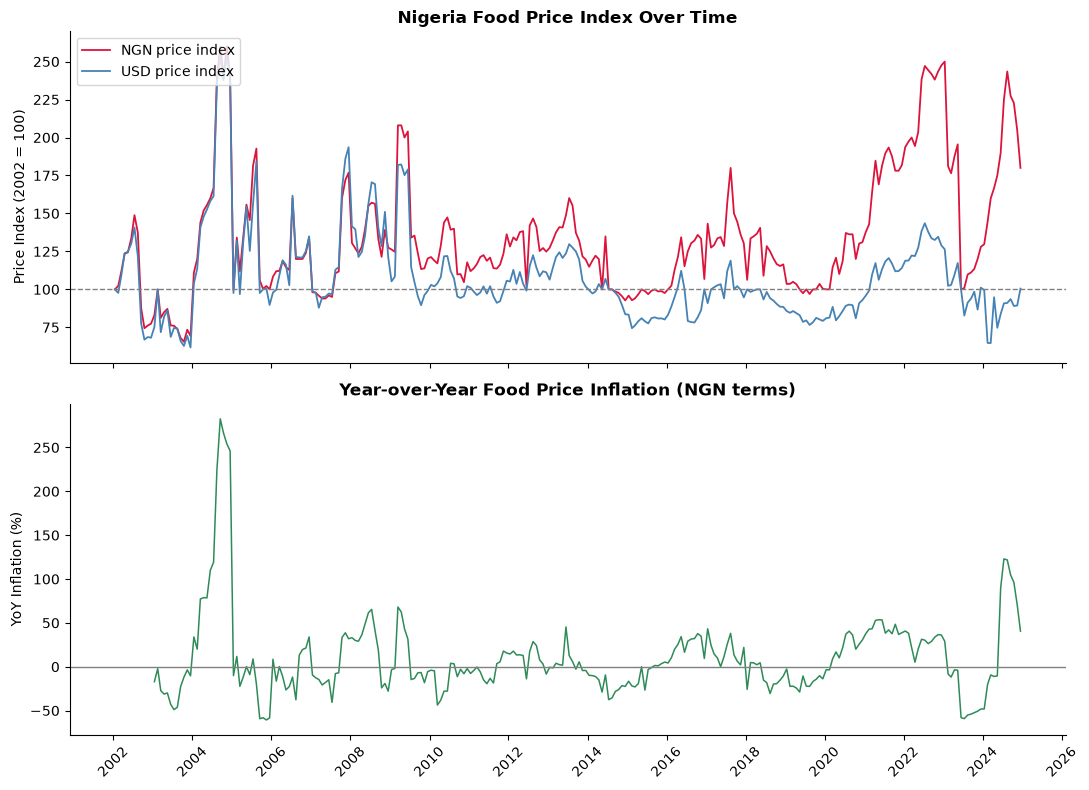

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(monthly_index.index, monthly_index.values, color='crimson', lw=1.3, label='NGN price index')
axes[0].plot(monthly_index_usd.index, monthly_index_usd.values, color='steelblue', lw=1.3, label='USD price index')
axes[0].axhline(100, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Price Index (2002 = 100)')
axes[0].set_title('Nigeria Food Price Index Over Time', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left')

axes[1].plot(yoy_inflation.index, yoy_inflation.values, color='seagreen', lw=1.1)
axes[1].axhline(0, color='gray', linewidth=1)
axes[1].set_ylabel('YoY Inflation (%)')
axes[1].set_title('Year-over-Year Food Price Inflation (NGN terms)', fontsize=12, fontweight='bold')
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Interpretation:**
- The **NGN index** (red) climbed from 100 in 2002 to roughly **180–250** by late 2024, in
  three distinct waves: 2004–05, 2008–09, and — by far the sharpest — **2021 to 2024**.
- The **USD index** (blue) is much flatter in that last wave. Since both lines track the same
  physical goods, the gap between them is almost entirely currency devaluation — i.e. Nigeria's
  recent food inflation is largely an exchange-rate story, not purely a supply-side one.
- **YoY inflation** peaked near **280%** in 2004–05 (very few series existed yet, so it's
  noisy) and again reached **120–165%** in 2024 — the most severe *sustained* period in the
  whole series.

### 3.4 Inflation broken down by food category

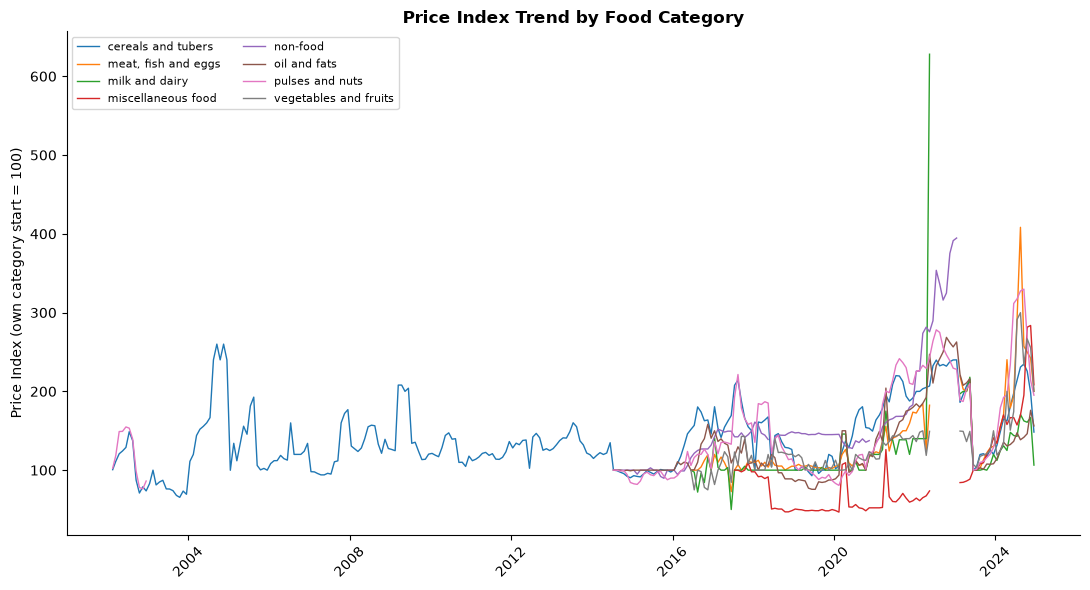

In [12]:
cat_first = df_sorted.groupby(['category', 'series_id'])['price'].transform('first')
df_sorted['cat_relative'] = df_sorted['price'] / cat_first * 100
cp1, cp99 = df_sorted['cat_relative'].quantile([0.01, 0.99])
df_sorted['cat_relative_clean'] = df_sorted['cat_relative'].clip(cp1, cp99)

cat_monthly = df_sorted.groupby(['date', 'category'])['cat_relative_clean'].median().unstack()

# Reindex to the full monthly calendar so months with no data show as a GAP in the line,
# instead of matplotlib drawing a misleading straight line across the missing months.
all_months = pd.date_range(df['date'].min(), df['date'].max(), freq='MS') + pd.Timedelta(days=14)
cat_monthly = cat_monthly.reindex(all_months)

fig, ax = plt.subplots(figsize=(11, 6))
for col in cat_monthly.columns:
    ax.plot(cat_monthly.index, cat_monthly[col], lw=1, label=col)
ax.set_title('Price Index Trend by Food Category', fontsize=12, fontweight='bold')
ax.set_ylabel('Price Index (own category start = 100)')
ax.legend(fontsize=8, ncol=2, loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**INTERPRETATION :** most non-cereal categories only start being reported around
2016–2017, so cross-category comparison is only meaningful from that point on. `Cereals and
tubers` is the only category with the full 2002–2024 history.

---
## 4. Task 1b — Wholesale vs. retail price spreads

### 4.1 Why raw prices can't be compared directly

Wholesale and retail prices are recorded in **different units** — wholesale is usually a bulk
unit like `"100 KG"`, retail is `"KG"` or a small fraction of a KG. Let's confirm that.

In [13]:
print("Units used for Wholesale prices:", sorted(df[df['pricetype']=='Wholesale']['unit'].unique()))
print("Units used for Retail prices:   ", sorted(df[df['pricetype']=='Retail']['unit'].unique()))


Units used for Wholesale prices: ['100 KG', '100 L', '100 Tubers', '50 KG', 'KG', 'L']
Units used for Retail prices:    ['0.5 KG', '1.1 KG', '1.2 KG', '1.3 KG', '1.4 KG', '1.5 KG', '100 L', '2.1 KG', '2.5 KG', '20 G', '250 G', '3.1 KG', '3.4 KG', '30 pcs', '300 G', '400 G', '500 G', '750 ML', 'KG', 'L', 'Unit']


As expected, wholesale uses bulk units and retail uses small ones. Comparing raw prices
would make wholesale look artificially expensive just because it's sold in 100kg bags.

### 4.2 Normalizing to a common "price per KG"

We convert every price to a **price per kilogram (or per litre)** using the unit string.
Some units (like `"Unit"`, `"100 Tubers"`, `"30 pcs"`) aren't weight/volume-based at all and
**can't** be converted — those rows are excluded from this specific comparison (they're
still used everywhere else in the notebook).

In [14]:
def unit_to_kg_factor(unit_string):
    """
    Parses a unit string like '100 KG', '1.5 KG', '750 ML' into how many
    KG or L it represents. Returns None for units that aren't weight/volume
    based (e.g. 'Unit', '100 Tubers') since those can't be converted.
    """
    unit_string = unit_string.strip()
    if unit_string in ('KG', 'L'):
        return 1.0
    match = re.match(r'^([\d.]+)\s*(KG|L|G|ML)$', unit_string)
    if not match:
        return None
    quantity, unit_type = float(match.group(1)), match.group(2)
    if unit_type == 'G':
        quantity = quantity / 1000    # grams -> KG
    elif unit_type == 'ML':
        quantity = quantity / 1000    # ml -> L
    return quantity

df['kg_factor'] = df['unit'].apply(unit_to_kg_factor)

n_not_convertible = df['kg_factor'].isnull().sum()
print(f"Rows with a non-weight/volume unit (excluded from this comparison only): {n_not_convertible:,} of {len(df):,}")

df_priced_per_kg = df.dropna(subset=['kg_factor']).copy()
df_priced_per_kg = df_priced_per_kg[df_priced_per_kg['kg_factor'] > 0]
df_priced_per_kg['price_per_kg'] = df_priced_per_kg['price'] / df_priced_per_kg['kg_factor']


Rows with a non-weight/volume unit (excluded from this comparison only): 3,600 of 76,810


### 4.3 Matching wholesale and retail on the same commodity, market, and month

Now that everything is on a per-KG basis, we can pair up wholesale and retail prices for the
*same* commodity, in the *same* market, in the *same* month, and look at the difference.

In [15]:
matched = df_priced_per_kg.pivot_table(
    index=['date', 'market', 'commodity'],
    columns='pricetype',
    values='price_per_kg',
    aggfunc='mean'
).reset_index()

matched = matched.dropna(subset=['Wholesale', 'Retail'])
matched['markup_pct'] = (matched['Retail'] - matched['Wholesale']) / matched['Wholesale'] * 100
matched = matched[np.isfinite(matched['markup_pct'])]

print(f"Matched wholesale-retail pairs: {len(matched):,}")


Matched wholesale-retail pairs: 8,006


A few of these matched pairs have an extreme markup (>1000%), almost certainly bad data
entries rather than real price differences. As in Task 1a, we trim the most extreme 1% on
each side before summarizing, so a handful of bad rows can't dominate the median/mean.

In [16]:
lo, hi = matched['markup_pct'].quantile([0.01, 0.99])
matched_trimmed = matched[(matched['markup_pct'] >= lo) & (matched['markup_pct'] <= hi)]

print(f"Median retail markup over wholesale: {matched_trimmed['markup_pct'].median():.1f}%")
print(f"Mean retail markup over wholesale:   {matched_trimmed['markup_pct'].mean():.1f}%")


Median retail markup over wholesale: 5.9%
Mean retail markup over wholesale:   14.4%


### 4.4 Plot: markup over time, and which commodities have the biggest markup

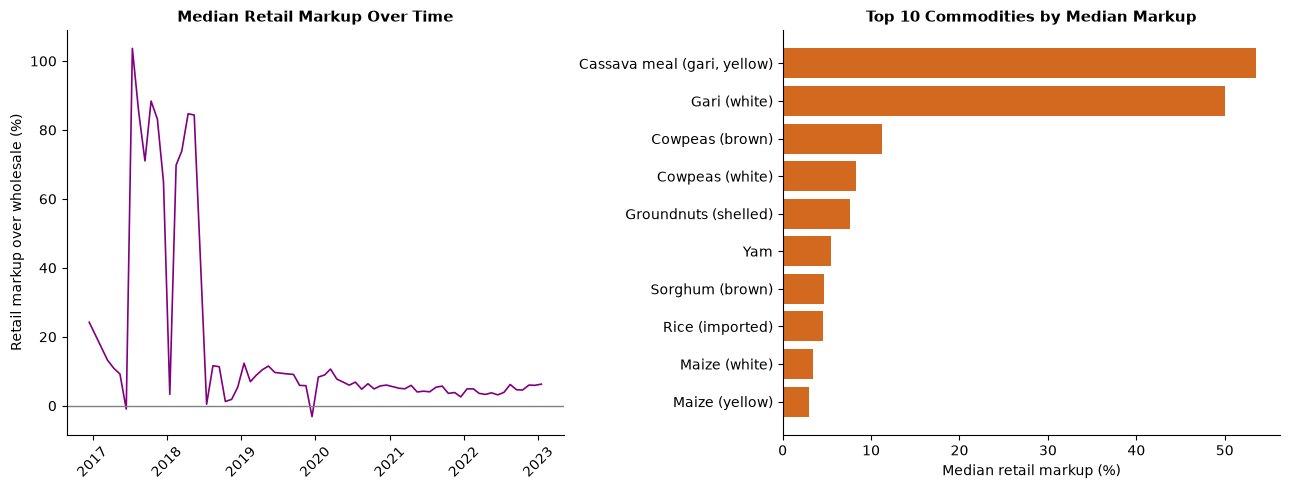

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

markup_over_time = matched_trimmed.groupby('date')['markup_pct'].median()
axes[0].plot(markup_over_time.index, markup_over_time.values, color='purple', lw=1.2)
axes[0].axhline(0, color='gray', lw=1)
axes[0].set_title('Median Retail Markup Over Time', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Retail markup over wholesale (%)')
plt.setp(axes[0].get_xticklabels(), rotation=45)

top10 = matched_trimmed.groupby('commodity')['markup_pct'].median().sort_values(ascending=False).head(10)
axes[1].barh(top10.index[::-1], top10.values[::-1], color='chocolate')
axes[1].set_title('Top 10 Commodities by Median Markup', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Median retail markup (%)')

plt.tight_layout()
plt.show()


**Interpretation:** across **8,000+ matched observations**, the typical (median) retail
markup is modest — around **6%** — and mean pulled higher by a few outlier commodities. The
markup was much more volatile before ~2019 and has settled into a tighter band since.
**Processed goods like gari (cassava meal)** carry by far the largest markup (~50%), since
they require actual processing/value-add between the wholesale and retail stage — unlike raw
grains such as maize or rice, which show only a 3–5% markup.

---
## 5. Task 1c — Geographic price hotspots

### 5.1 Market-level view: retail maize prices

Using latitude/longitude, we can plot each market as a point on a scatter map, colored by
its average retail price. Maize is used here since it's the most consistently reported
commodity across markets and time.

In [18]:
maize_retail = df[(df['commodity'] == 'Maize (white)') &
                   (df['unit'] == 'KG') &
                   (df['pricetype'] == 'Retail')]

market_avg = maize_retail.groupby(['market', 'latitude', 'longitude'])['usdprice'].mean().reset_index()
print(f"Markets with retail maize data: {len(market_avg)}")


Markets with retail maize data: 16


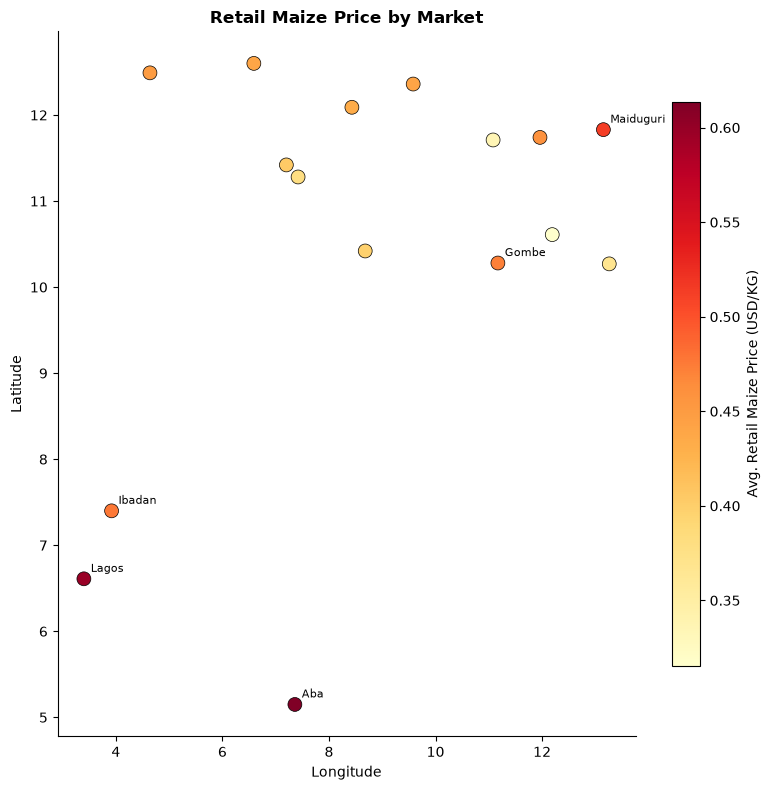

In [19]:
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(market_avg['longitude'], market_avg['latitude'], c=market_avg['usdprice'],
                 cmap='YlOrRd', s=100, edgecolor='black', linewidth=0.5)
plt.colorbar(sc, ax=ax, label='Avg. Retail Maize Price (USD/KG)', shrink=0.8)

# Label the 5 most expensive markets
for _, row in market_avg.nlargest(5, 'usdprice').iterrows():
    ax.annotate(row['market'], (row['longitude'], row['latitude']), fontsize=8,
                xytext=(5, 5), textcoords='offset points')

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Retail Maize Price by Market', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpretation:** Lagos and Aba (south) are the clear hotspots, at roughly
**$0.55–0.60/KG** — major consumer cities far from the growing regions. Northern markets near
the producing belt (Katsina, Gombe, Sokoto-area) are cheaper, around $0.32–0.38/KG.

### 5.2 State-level view: why a simple average is misleading

A naive "average price per state" is biased by *which* commodities that state happens to
report — a state that mostly reports cheap cereals will look artificially "cheap" even if
every individual item there is expensive. The fix: express every price **relative to the
national average for that specific commodity/unit/price-type**, so a value of 1.2 means
"20% above the national average for that same item" — then average those relatives per
state. This removes the commodity-mix bias.

In [20]:
series_key = ['commodity', 'unit', 'pricetype']
national_avg = df.groupby(series_key)['usdprice'].transform('mean')
df['price_vs_national'] = df['usdprice'] / national_avg

state_index = df.groupby('admin1')['price_vs_national'].median()
state_location = df.groupby('admin1')[['latitude', 'longitude']].mean()
state_summary = state_location.join(state_index.rename('relative_price'))

print("Top 5 most expensive states (relative to national average):")
print(state_summary.sort_values('relative_price', ascending=False).head(5))
print()
print("Top 5 cheapest states (relative to national average):")
print(state_summary.sort_values('relative_price').head(5))


Top 5 most expensive states (relative to national average):
        latitude  longitude  relative_price
admin1                                     
Abia     5.15000   7.360000        1.352257
Lagos    6.61000   3.400000        1.104153
Oyo      7.40000   3.920000        1.041915
Gombe   10.28000  11.170000        0.968588
Borno   11.74418  13.099953        0.967131

Top 5 cheapest states (relative to national average):
          latitude  longitude  relative_price
admin1                                       
Yobe     12.202743  11.410190        0.886808
Jigawa   12.420102   9.559966        0.893310
Zamfara  12.600000   6.590000        0.903941
Katsina  11.989969   7.386411        0.921722
Kano     12.090000   8.430000        0.941220


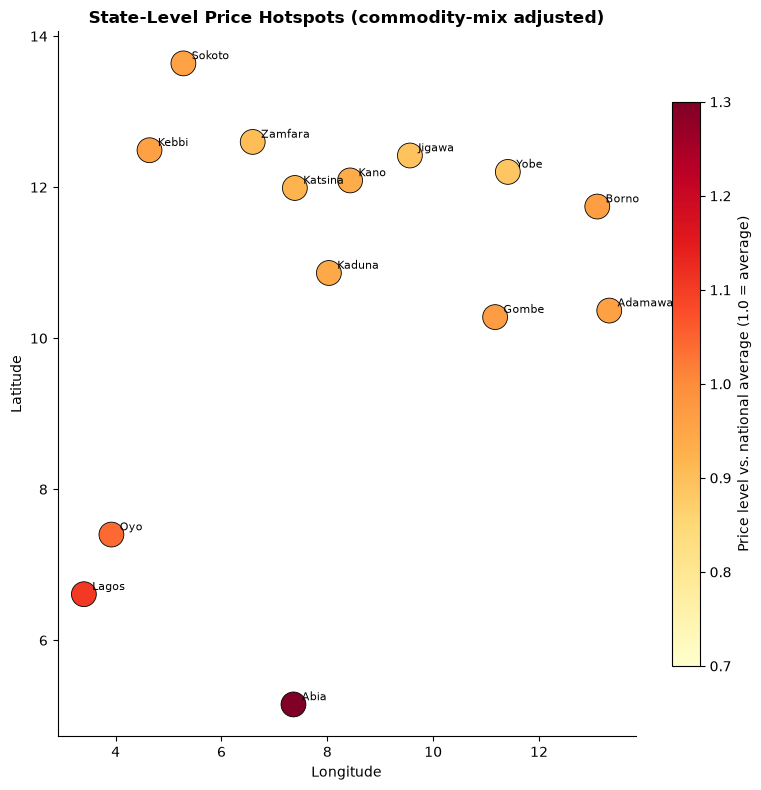

In [21]:
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(state_summary['longitude'], state_summary['latitude'], c=state_summary['relative_price'],
                 cmap='YlOrRd', s=320, edgecolor='black', linewidth=0.6, vmin=0.7, vmax=1.3)
for state, row in state_summary.iterrows():
    ax.annotate(state, (row['longitude'], row['latitude']), fontsize=8,
                xytext=(6, 3), textcoords='offset points')
plt.colorbar(sc, ax=ax, label='Price level vs. national average (1.0 = average)', shrink=0.8)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('State-Level Price Hotspots (commodity-mix adjusted)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpretation:** Abia (+35%), Lagos (+10%), and Oyo (+4%) are the most expensive
states relative to the national average — all southern, urban/consumer states. Yobe, Jigawa,
Zamfara, and Katsina (all northern) are the cheapest, 8–11% below average. This matches the
expected pattern for an agrarian economy: **prices rise as food travels from northern
production zones to southern consumption centers**, reflecting transport costs and demand.

---
## 6. Summary

**Data quality:** no missing values, no duplicates, no invalid prices in this dataset —
verified explicitly rather than assumed. ~32% of rows are WFP aggregate/estimated prices
rather than directly observed ones (kept in the analysis, but worth knowing).

**1a — Inflation:** food prices are roughly 2–2.5x higher (NGN terms) than in 2002, with the
sharpest and most sustained rise from 2021–2024. Comparing to the USD-terms index shows most
of that recent rise is currency devaluation rather than a pure food-supply shock.

**1b — Wholesale vs. retail:** after normalizing for unit differences, the typical retail
markup over wholesale is a modest ~6% (median), and has been stable in a 3–10% band since
2020. Processed goods (gari) carry much higher markups (~50%) than raw staples (~3–5%).

**1c — Geography:** food is consistently more expensive in southern consumer cities (Lagos,
Abia, Oyo) and cheaper in northern producing states (Yobe, Jigawa, Zamfara, Katsina) — a
clear north-to-south price gradient driven by distance from production to market.
